# Day 4 — Delivery Time Prediction



## 1. Imports and paths

In [1]:
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.model_selection import train_test_split,KFold,cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge,Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
ROOT=Path.cwd().parent if Path.cwd().name=="notebooks" else Path.cwd()
RAW=ROOT/"data/raw"; PROCESSED=ROOT/"data/processed"; OUT=ROOT/"outputs/delivery_time_prediction"; MODELS=ROOT/"models"
for p in [PROCESSED,OUT,MODELS]: p.mkdir(parents=True,exist_ok=True)
orders=pd.read_csv(RAW/"orders.csv",parse_dates=["order_timestamp"]); deliveries=pd.read_csv(RAW/"deliveries.csv"); restaurants=pd.read_csv(RAW/"restaurants.csv")
print("orders",orders.shape,"deliveries",deliveries.shape,"restaurants",restaurants.shape)

orders (1800, 8) deliveries (1800, 9) restaurants (45, 6)


## 2. Feature engineering and target selection
Merge order and restaurant data. Use only completed deliveries with valid positive target times. IDs and target are excluded from predictors.

In [2]:
data=deliveries.merge(orders,on="order_id",how="left",validate="one_to_one").merge(restaurants[["restaurant_id","category","restaurant_rating","avg_prep_time_minutes"]],on="restaurant_id",how="left",validate="many_to_one")
data=data[data.delivery_status.astype(str).str.lower().eq("completed") & data.delivery_time_minutes.notna() & (data.delivery_time_minutes>0)].copy()
data["order_hour"]=data.order_timestamp.dt.hour; data["day_of_week"]=data.order_timestamp.dt.dayofweek
data["is_weekend"]=(data.day_of_week>=5).astype(int); data["is_late_night"]=((data.order_hour>=22)|(data.order_hour<5)).astype(int)
segfile=PROCESSED/"customer_features_clustered.csv"
if segfile.exists():
 seg=pd.read_csv(segfile)
 if {"customer_id","kmeans_cluster"}.issubset(seg.columns): data=data.merge(seg[["customer_id","kmeans_cluster"]].rename(columns={"kmeans_cluster":"customer_segment"}),on="customer_id",how="left",validate="many_to_one")
 else: data["customer_segment"]="unknown"
else: data["customer_segment"]="unknown"
print("Completed delivery rows:",len(data)); display(data.delivery_time_minutes.describe().to_frame())

Completed delivery rows: 1624


,delivery_time_minutes
count,1624.000000
mean,52.700123
std,15.859693
min,11.000000
25%,41.000000
50%,51.000000
75%,62.000000
max,125.000000


## 3. EDA — distribution, outliers and correlations

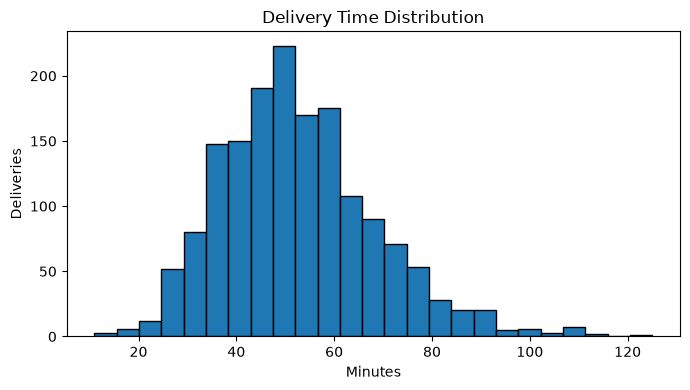

,delivery_time_minutes,delivery_distance_km,order_amount_inr,number_of_items,preparation_time_minutes,restaurant_rating
count,1624.00,1624.00,1624.00,1624.00,1624.00,1624.00
mean,52.70,4.28,537.32,4.46,22.19,3.97
std,15.86,2.97,337.25,2.31,7.89,0.55
min,11.00,0.40,90.00,1.00,8.00,2.70
25%,41.00,2.07,285.98,2.00,15.00,3.70
50%,51.00,3.56,461.91,4.00,23.00,3.90
75%,62.00,5.83,707.73,6.00,30.00,4.30
max,125.00,18.00,2200.00,8.00,35.00,5.00


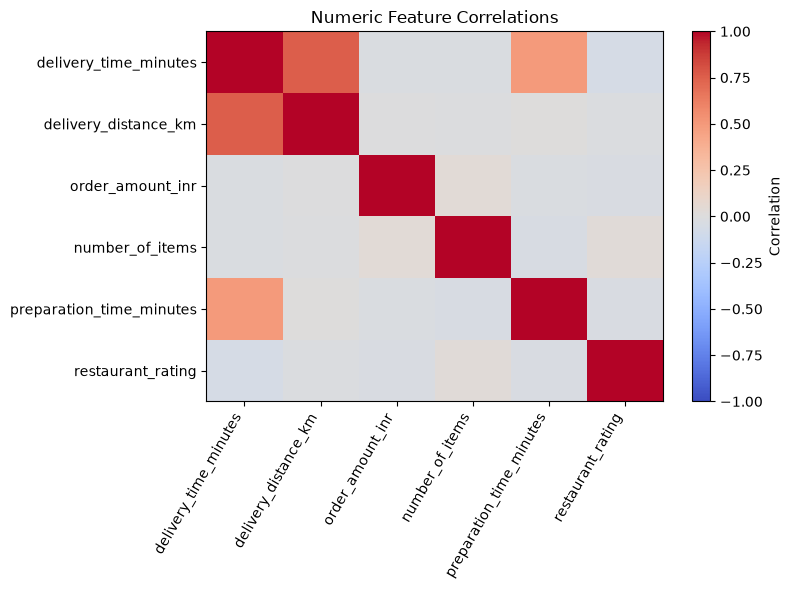

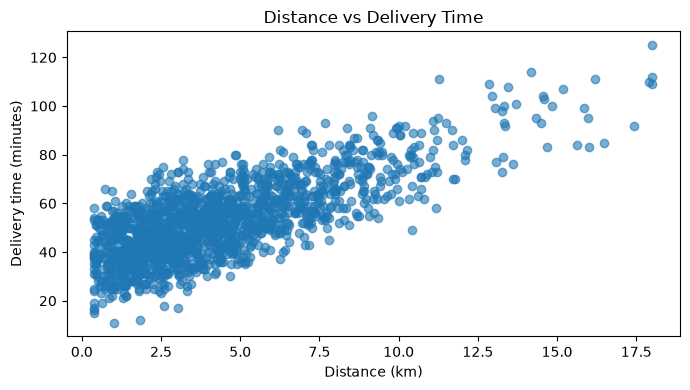

Potential target outliers (1.5 x IQR): 24


In [3]:
plt.figure(figsize=(7,4)); plt.hist(data.delivery_time_minutes,bins=25,edgecolor="black"); plt.title("Delivery Time Distribution"); plt.xlabel("Minutes"); plt.ylabel("Deliveries"); plt.tight_layout(); plt.savefig(OUT/"delivery_time_distribution.png",dpi=150); plt.show()
num=["delivery_time_minutes","delivery_distance_km","order_amount_inr","number_of_items","preparation_time_minutes","restaurant_rating"]; num=[c for c in num if c in data]; display(data[num].describe().round(2))
corr=data[num].corr(numeric_only=True); plt.figure(figsize=(8,6)); plt.imshow(corr,cmap="coolwarm",vmin=-1,vmax=1,aspect="auto"); plt.xticks(range(len(corr)),corr.columns,rotation=60,ha="right"); plt.yticks(range(len(corr)),corr.index); plt.colorbar(label="Correlation"); plt.title("Numeric Feature Correlations"); plt.tight_layout(); plt.savefig(OUT/"delivery_correlation_matrix.png",dpi=150); plt.show()
plt.figure(figsize=(7,4)); plt.scatter(data.delivery_distance_km,data.delivery_time_minutes,alpha=.6); plt.xlabel("Distance (km)"); plt.ylabel("Delivery time (minutes)"); plt.title("Distance vs Delivery Time"); plt.tight_layout(); plt.savefig(OUT/"distance_vs_delivery_time.png",dpi=150); plt.show()
q1,q3=data.delivery_time_minutes.quantile([.25,.75]); iqr=q3-q1; print("Potential target outliers (1.5 x IQR):",int(((data.delivery_time_minutes<q1-1.5*iqr)|(data.delivery_time_minutes>q3+1.5*iqr)).sum()))

## 4. Train/test split and preprocessing
Numeric features are imputed and standardized. Categorical features are imputed and one-hot encoded. Preprocessing is fitted inside each pipeline to avoid leakage.

In [4]:
TARGET="delivery_time_minutes"
num_features=["delivery_distance_km","order_amount_inr","number_of_items","preparation_time_minutes","restaurant_rating","avg_prep_time_minutes","order_hour","day_of_week","is_weekend","is_late_night"]
cat_features=["weather","traffic_condition","category","customer_segment"]
num_features=[c for c in num_features if c in data]; cat_features=[c for c in cat_features if c in data]; features=num_features+cat_features
model_data=data[features+[TARGET]].replace([np.inf,-np.inf],np.nan).dropna(subset=[TARGET]).copy(); X=model_data[features]; y=model_data[TARGET].astype(float)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=42)
num_pipe=Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())]); cat_pipe=Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))])
prep=ColumnTransformer([("num",num_pipe,num_features),("cat",cat_pipe,cat_features)])
print("Rows:",len(model_data),"train:",len(X_train),"test:",len(X_test)); print("Features:",features)

Rows: 1624 train: 1299 test: 325
Features: ['delivery_distance_km', 'order_amount_inr', 'number_of_items', 'preparation_time_minutes', 'restaurant_rating', 'avg_prep_time_minutes', 'order_hour', 'day_of_week', 'is_weekend', 'is_late_night', 'weather', 'traffic_condition', 'category', 'customer_segment']


## 5. Train four regression approaches and compare MAE, RMSE and R²

In [5]:
estimators={"Mean baseline":DummyRegressor(strategy="mean"),"Ridge":Ridge(alpha=1.0),"Lasso":Lasso(alpha=.1,max_iter=10000),"Random Forest":RandomForestRegressor(n_estimators=250,min_samples_leaf=2,random_state=42,n_jobs=-1)}
pipes={name:Pipeline([("preprocessor",prep),("model",est)]) for name,est in estimators.items()}; fitted={}; preds={}; rows=[]
for name,pipe in pipes.items():
 pipe.fit(X_train,y_train); pred=pipe.predict(X_test); fitted[name]=pipe; preds[name]=pred
 rows.append({"model":name,"MAE":mean_absolute_error(y_test,pred),"RMSE":mean_squared_error(y_test,pred)**.5,"R2":r2_score(y_test,pred)})
comparison=pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True); display(comparison.round(3)); comparison.to_csv(OUT/"regression_model_comparison.csv",index=False)

,model,MAE,RMSE,R2
0,Ridge,3.939,4.940,0.906
1,Lasso,3.979,4.975,0.905
2,Random Forest,4.647,5.836,0.869
3,Mean baseline,12.628,16.111,-0.000


## 6. Cross-validation on training data

In [6]:
cv=KFold(n_splits=5,shuffle=True,random_state=42); cvrows=[]
for name,pipe in pipes.items():
 scores=cross_validate(pipe,X_train,y_train,cv=cv,scoring={"mae":"neg_mean_absolute_error","r2":"r2"})
 cvrows.append({"model":name,"cv_MAE_mean":-scores["test_mae"].mean(),"cv_MAE_std":scores["test_mae"].std(),"cv_R2_mean":scores["test_r2"].mean()})
cv_results=pd.DataFrame(cvrows).sort_values("cv_MAE_mean"); display(cv_results.round(3)); cv_results.to_csv(OUT/"regression_cross_validation.csv",index=False)

,model,cv_MAE_mean,cv_MAE_std,cv_R2_mean
2,Lasso,3.959,0.077,0.899
1,Ridge,3.965,0.088,0.899
3,Random Forest,4.706,0.189,0.859
0,Mean baseline,12.316,0.555,-0.001


## 7. Actual vs predicted and feature importance

Best model by test MAE: Ridge


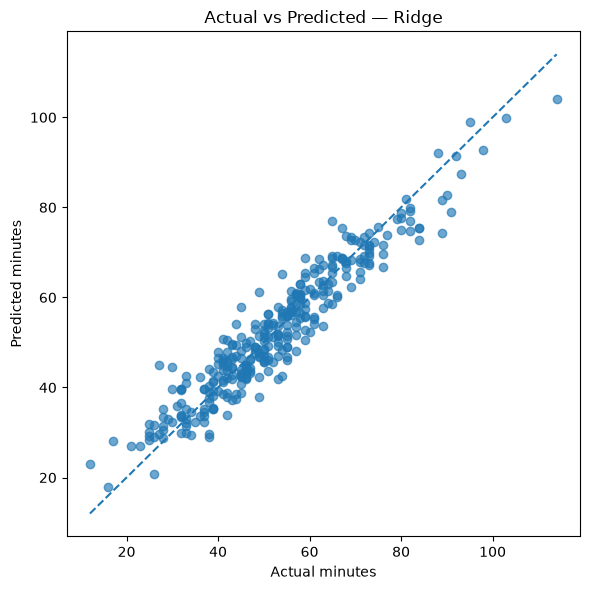

,feature,importance
0,num__delivery_distance_km,0.619214
3,num__preparation_time_minutes,0.127779
5,num__avg_prep_time_minutes,0.114626
14,cat__traffic_condition_High,0.026332
13,cat__weather_Rain,0.024506
1,num__order_amount_inr,0.015142
6,num__order_hour,0.013456
15,cat__traffic_condition_Low,0.012304
2,num__number_of_items,0.009581
7,num__day_of_week,0.008664


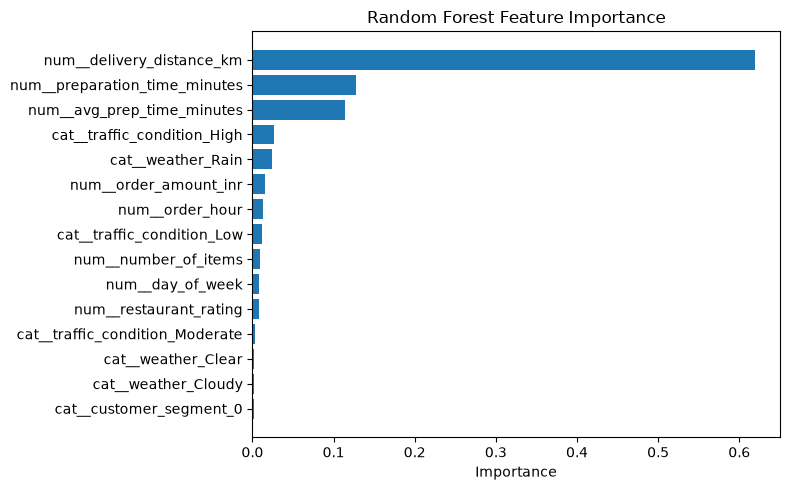

In [7]:
best_name=comparison.iloc[0]["model"]; best=fitted[best_name]; best_pred=preds[best_name]; print("Best model by test MAE:",best_name)
lo=min(float(y_test.min()),float(np.min(best_pred))); hi=max(float(y_test.max()),float(np.max(best_pred)))
plt.figure(figsize=(6,6)); plt.scatter(y_test,best_pred,alpha=.65); plt.plot([lo,hi],[lo,hi],"--"); plt.xlabel("Actual minutes"); plt.ylabel("Predicted minutes"); plt.title("Actual vs Predicted — "+best_name); plt.tight_layout(); plt.savefig(OUT/"actual_vs_predicted_delivery_time.png",dpi=150); plt.show()
pd.DataFrame({"actual_delivery_time_minutes":y_test,"predicted_delivery_time_minutes":best_pred},index=y_test.index).to_csv(OUT/"actual_vs_predicted.csv")
rf=fitted["Random Forest"]; names=rf.named_steps["preprocessor"].get_feature_names_out(); imp=rf.named_steps["model"].feature_importances_; importance=pd.DataFrame({"feature":names,"importance":imp}).sort_values("importance",ascending=False); display(importance.head(20)); importance.to_csv(OUT/"random_forest_feature_importance.csv",index=False)
top=importance.head(15).sort_values("importance"); plt.figure(figsize=(8,5)); plt.barh(top.feature,top.importance); plt.xlabel("Importance"); plt.title("Random Forest Feature Importance"); plt.tight_layout(); plt.savefig(OUT/"random_forest_feature_importance.png",dpi=150); plt.show()

## 8. Save model and business recommendation

In [8]:
joblib.dump(best,MODELS/"delivery_time_best_model.joblib"); model_data.to_csv(PROCESSED/"delivery_time_model_dataset.csv",index=False)
r=comparison.iloc[0]; message=f"Best model by test MAE: {best_name}; MAE={r.MAE:.2f} minutes; RMSE={r.RMSE:.2f} minutes; R2={r.R2:.3f}. Inspect the Random Forest feature importance for influential predictors. Results are based on synthetic data and need validation on real operational data."
print(message); (OUT/"model_recommendation.txt").write_text(message+"\n",encoding="utf-8")

Best model by test MAE: Ridge; MAE=3.94 minutes; RMSE=4.94 minutes; R2=0.906. Inspect the Random Forest feature importance for influential predictors. Results are based on synthetic data and need validation on real operational data.


233